### E-Commerce RTO Prediction (Logistic_regression With Pipeline)

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_excel("ecommerce_rto_prediction_dataset.xlsx")

In [3]:
df.head()

,order_id,order_date,city_tier,payment_mode,product_category,customer_type,past_orders,past_rto_count,order_value_inr,discount_pct,order_hour,is_sale_day,phone_verified,address_quality_score,pincode_risk_score,promised_delivery_days,courier_partner,is_rto
0,ORD500001,2025-12-11,Tier-2,COD,Footwear,Repeat,3,1,259,48.0,22,0,0,72.0,30.3,10,Delhivery,0
1,ORD500002,2025-08-17,Rural,Prepaid,Fashion,New,0,0,461,32.0,20,0,1,69.0,16.9,8,Shadowfax,0
2,ORD500003,2025-09-07,Rural,Prepaid,Home & Kitchen,New,0,0,969,3.0,19,0,0,69.0,48.1,8,India Post,0
3,ORD500004,2025-11-24,Tier-3,Prepaid,Accessories,New,0,0,1174,32.0,22,0,1,51.0,38.7,4,Xpressbees,0
4,ORD500005,2025-07-31,Tier-2,Prepaid,Electronics,New,0,0,3758,58.0,19,0,0,79.0,4.0,5,Delhivery,0


In [4]:
df.tail()

,order_id,order_date,city_tier,payment_mode,product_category,customer_type,past_orders,past_rto_count,order_value_inr,discount_pct,order_hour,is_sale_day,phone_verified,address_quality_score,pincode_risk_score,promised_delivery_days,courier_partner,is_rto
10995,ORD510996,2025-10-11,Rural,Prepaid,Home & Kitchen,New,0,0,783,47.0,21,0,1,57.0,53.2,6,Delhivery,0
10996,ORD510997,2025-08-12,Tier-2,COD,Beauty,Repeat,6,0,537,26.0,21,0,1,100.0,18.8,3,Shadowfax,0
10997,ORD510998,2025-07-28,Tier-2,COD,Fashion,Repeat,2,0,681,39.0,23,0,1,98.0,29.9,8,India Post,0
10998,ORD510999,2025-01-09,Tier-2,COD,Fashion,Repeat,3,0,241,62.0,21,0,0,98.0,33.8,6,Ecom Express,0
10999,ORD511000,2025-11-24,Rural,Prepaid,Fashion,Repeat,2,0,290,36.0,21,0,1,74.0,39.2,7,Ecom Express,0


In [5]:
df.sample(5)

,order_id,order_date,city_tier,payment_mode,product_category,customer_type,past_orders,past_rto_count,order_value_inr,discount_pct,order_hour,is_sale_day,phone_verified,address_quality_score,pincode_risk_score,promised_delivery_days,courier_partner,is_rto
1261,ORD501262,2025-07-20,Tier-2,COD,Home & Kitchen,New,0,0,420,18.0,20,0,0,90.0,42.7,7,Delhivery,0
3051,ORD503052,2025-01-26,Tier-2,Prepaid,Fashion,New,0,0,774,24.0,13,0,0,50.0,45.4,5,Ecom Express,0
3145,ORD503146,2025-10-08,Tier-3,Prepaid,Home & Kitchen,New,0,0,1717,38.0,21,0,0,58.0,46.2,5,Shadowfax,0
910,ORD500911,2025-06-02,Metro,Prepaid,Footwear,Repeat,5,0,644,20.0,19,0,1,100.0,8.3,2,Delhivery,0
9748,ORD509749,2025-04-25,Metro,Prepaid,Home & Kitchen,New,0,0,406,40.0,9,0,1,63.0,9.0,4,Delhivery,0


In [6]:
df.drop(["order_date", "order_id"], axis=1, inplace=True)

In [7]:
df.shape

(11000, 16)

In [8]:
df.columns

Index(['city_tier', 'payment_mode', 'product_category', 'customer_type',
       'past_orders', 'past_rto_count', 'order_value_inr', 'discount_pct',
       'order_hour', 'is_sale_day', 'phone_verified', 'address_quality_score',
       'pincode_risk_score', 'promised_delivery_days', 'courier_partner',
       'is_rto'],
      dtype='str')

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11000 entries, 0 to 10999
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   city_tier               11000 non-null  str    
 1   payment_mode            11000 non-null  str    
 2   product_category        11000 non-null  str    
 3   customer_type           11000 non-null  str    
 4   past_orders             11000 non-null  int64  
 5   past_rto_count          11000 non-null  int64  
 6   order_value_inr         11000 non-null  int64  
 7   discount_pct            10780 non-null  float64
 8   order_hour              11000 non-null  int64  
 9   is_sale_day             11000 non-null  int64  
 10  phone_verified          11000 non-null  int64  
 11  address_quality_score   10725 non-null  float64
 12  pincode_risk_score      10835 non-null  float64
 13  promised_delivery_days  11000 non-null  int64  
 14  courier_partner         10890 non-null  str    
 

In [10]:
df.describe()

,past_orders,past_rto_count,order_value_inr,discount_pct,order_hour,is_sale_day,phone_verified,address_quality_score,pincode_risk_score,promised_delivery_days,is_rto
count,11000.000000,11000.000000,11000.000000,10780.000000,11000.000000,11000.000000,11000.000000,10725.000000,10835.000000,11000.000000,11000.000000
mean,2.240727,0.260545,814.959455,32.293228,14.701818,0.120000,0.785000,71.637110,31.739732,6.009182,0.243091
std,2.821935,0.576006,2978.815980,14.898152,5.964010,0.324976,0.410841,15.452028,16.421086,1.989062,0.428969
min,0.000000,0.000000,149.000000,0.000000,0.000000,0.000000,0.000000,12.000000,0.400000,2.000000,0.000000
25%,0.000000,0.000000,342.000000,22.000000,10.000000,0.000000,1.000000,61.000000,19.200000,5.000000,0.000000
50%,0.000000,0.000000,545.000000,32.000000,16.000000,0.000000,1.000000,72.000000,29.700000,6.000000,0.000000
75%,5.000000,0.000000,874.250000,42.000000,20.000000,0.000000,1.000000,83.000000,42.500000,7.000000,0.000000
max,13.000000,5.000000,88890.000000,80.000000,23.000000,1.000000,1.000000,100.000000,90.600000,12.000000,1.000000


In [11]:
df.dtypes

city_tier                     str
payment_mode                  str
product_category              str
customer_type                 str
past_orders                 int64
past_rto_count              int64
order_value_inr             int64
discount_pct              float64
order_hour                  int64
is_sale_day                 int64
phone_verified              int64
address_quality_score     float64
pincode_risk_score        float64
promised_delivery_days      int64
courier_partner               str
is_rto                      int64
dtype: object

In [12]:
df.isnull().sum()

city_tier                   0
payment_mode                0
product_category            0
customer_type               0
past_orders                 0
past_rto_count              0
order_value_inr             0
discount_pct              220
order_hour                  0
is_sale_day                 0
phone_verified              0
address_quality_score     275
pincode_risk_score        165
promised_delivery_days      0
courier_partner           110
is_rto                      0
dtype: int64

In [13]:
df.duplicated().sum()

np.int64(0)

### Columns Distribution

In [14]:
cat_cols = df.select_dtypes(include = "object").columns

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_8196\2122677990.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include = "object").columns


In [15]:
cat_cols

Index(['city_tier', 'payment_mode', 'product_category', 'customer_type',
       'courier_partner'],
      dtype='str')

In [16]:
num_cols = df.select_dtypes(exclude = "object").columns.drop("is_rto")

In [17]:
num_cols

Index(['past_orders', 'past_rto_count', 'order_value_inr', 'discount_pct',
       'order_hour', 'is_sale_day', 'phone_verified', 'address_quality_score',
       'pincode_risk_score', 'promised_delivery_days'],
      dtype='str')

### Features & Targets

In [18]:
features = df.drop(["is_rto"], axis =1)
targets = df["is_rto"]

In [19]:
features.head()

,city_tier,payment_mode,product_category,customer_type,past_orders,past_rto_count,order_value_inr,discount_pct,order_hour,is_sale_day,phone_verified,address_quality_score,pincode_risk_score,promised_delivery_days,courier_partner
0,Tier-2,COD,Footwear,Repeat,3,1,259,48.0,22,0,0,72.0,30.3,10,Delhivery
1,Rural,Prepaid,Fashion,New,0,0,461,32.0,20,0,1,69.0,16.9,8,Shadowfax
2,Rural,Prepaid,Home & Kitchen,New,0,0,969,3.0,19,0,0,69.0,48.1,8,India Post
3,Tier-3,Prepaid,Accessories,New,0,0,1174,32.0,22,0,1,51.0,38.7,4,Xpressbees
4,Tier-2,Prepaid,Electronics,New,0,0,3758,58.0,19,0,0,79.0,4.0,5,Delhivery


In [20]:
targets.head()

0    0
1    0
2    0
3    0
4    0
Name: is_rto, dtype: int64

### Target Variable Balance check

In [21]:
df['is_rto'].value_counts()       #Order deliver = 0,   #Order Return = 1

is_rto
0    8326
1    2674
Name: count, dtype: int64

### Train & Split

In [22]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split (features, targets, test_size = 0.2, random_state = 42)

In [23]:
x_train.head()

,city_tier,payment_mode,product_category,customer_type,past_orders,past_rto_count,order_value_inr,discount_pct,order_hour,is_sale_day,phone_verified,address_quality_score,pincode_risk_score,promised_delivery_days,courier_partner
10735,Rural,COD,Fashion,New,0,0,264,43.0,10,0,0,46.0,54.2,3,Shadowfax
5937,Metro,Prepaid,Footwear,Repeat,8,1,363,16.0,21,0,1,54.0,11.4,9,Delhivery
7642,Metro,Prepaid,Fashion,New,0,0,407,21.0,17,0,1,47.0,18.3,6,Ecom Express
3328,Tier-3,COD,Beauty,Repeat,8,0,1745,19.0,10,0,1,70.0,64.7,5,Delhivery
8681,Metro,COD,Footwear,Repeat,4,0,390,68.0,22,0,1,48.0,3.3,3,Xpressbees


In [24]:
x_test.head()

,city_tier,payment_mode,product_category,customer_type,past_orders,past_rto_count,order_value_inr,discount_pct,order_hour,is_sale_day,phone_verified,address_quality_score,pincode_risk_score,promised_delivery_days,courier_partner
107,Metro,COD,Fashion,Repeat,4,0,310,30.0,21,0,1,74.0,25.3,5,Shadowfax
5484,Tier-2,COD,Fashion,Repeat,3,1,728,29.0,20,0,1,75.0,23.4,10,Shadowfax
6998,Tier-3,COD,Accessories,Repeat,2,0,173,34.0,8,0,1,36.0,56.7,6,India Post
3984,Tier-3,Prepaid,Home & Kitchen,New,0,0,446,48.0,14,0,1,51.0,41.6,11,Xpressbees
3111,Metro,Prepaid,Beauty,Repeat,8,1,266,49.0,6,0,0,78.0,40.6,5,Ecom Express


In [25]:
y_train.head()

10735    1
5937     0
7642     0
3328     0
8681     0
Name: is_rto, dtype: int64

In [26]:
y_test.head()

107     0
5484    0
6998    0
3984    0
3111    0
Name: is_rto, dtype: int64

### Numeric pipeline: Imputer -> Scaler

In [27]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_pipe = Pipeline([
    ("imputer",  SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

### Categorical pipeline: Imputer -> OneHotEncoder

In [28]:
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

### ColumnTranformer

In [29]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer([
    ("numerical", num_pipe, num_cols),
    ("categorical", cat_pipe, cat_cols)
])

### Final pipeline = Processor + LogisticRegression

In [30]:
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LogisticRegression())
])

### Training

In [31]:
model.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['city_tier','payment_mode','product_category',...,'pincode_risk_score', 'promised_delivery_days','courier_partner']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default

### Test Data Prediction

In [32]:
y_pred_test = model.predict(x_test)
y_pred_train = model.predict(x_train)

### Model Evalution

In [33]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# Test metrics
accuracy1 = accuracy_score(y_test, y_pred_test)
accuracy2 = accuracy_score(y_train, y_pred_train)
precision = precision_score(y_test, y_pred_test)
recall = recall_score(y_test, y_pred_test)
f1 = f1_score(y_test, y_pred_test)
conf_matrix = confusion_matrix(y_test, y_pred_test)
class_report = classification_report(y_test, y_pred_test)

print(f"Test Accuracy : {accuracy1:.4f}")
print(f"Train Accuracy : {accuracy2:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print("\nConfusion Matrix:\n", conf_matrix)
print("\nClassification Report:\n", class_report)

Test Accuracy : 0.7727
Train Accuracy : 0.7722
Precision: 0.5596
Recall   : 0.2065
F1 Score : 0.3017

Confusion Matrix:
 [[1592   85]
 [ 415  108]]

Classification Report:
               precision    recall  f1-score   support

           0       0.79      0.95      0.86      1677
           1       0.56      0.21      0.30       523

    accuracy                           0.77      2200
   macro avg       0.68      0.58      0.58      2200
weighted avg       0.74      0.77      0.73      2200



### Confusion Matrix Heatmap

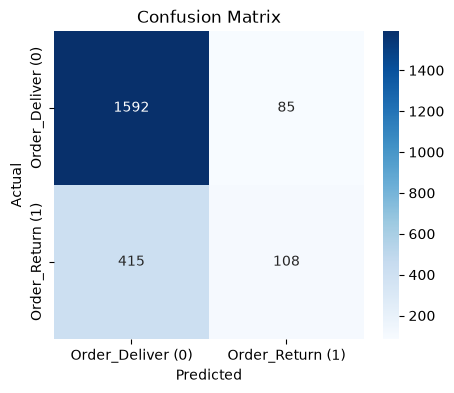

In [34]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_test)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Order_Deliver (0)', 'Order_Return (1)'],
            yticklabels=['Order_Deliver (0)', 'Order_Return (1)'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

### Pickle import

In [35]:
import pickle

# Assuming 'model' is your trained machine learning model
# Open a file in write-binary mode
with open('my_model.pkl', 'wb') as file:
    pickle.dump(model, file)

print("Model successfully pickled!")


Model successfully pickled!


In [36]:
import pickle
import pandas as pd

# 1. Define the input features matching your column headers
# Note: We completely exclude 'order_id', 'order_date', and the target 'is_rto' column
column_names = [
    'city_tier',
    'payment_mode',
    'product_category',
    'customer_type',
    'past_orders',
    'past_rto_count',
    'order_value_inr',
    'discount_pct',
    'order_hour',
    'is_sale_day',
    'phone_verified',
    'address_quality_score',
    'pincode_risk_score',
    'promised_delivery_days',
    'courier_partner'
]

# 2. Parse the raw values into their proper data types
row_values = [
    'Tier-2',      # city_tier (string)
    'COD',         # payment_mode (string)
    'Footwear',    # product_category (string)
    'Repeat',      # customer_type (string)
    3,             # past_orders (int)
    1,             # past_rto_count (int)
    259,           # order_value_inr (int/float)
    48.0,          # discount_pct (float)
    22,            # order_hour (int)
    0,             # is_sale_day (int)
    0,             # phone_verified (int)
    72.0,          # address_quality_score (float)
    30.3,          # pincode_risk_score (float)
    10,            # promised_delivery_days (int)
    'Delhivery'    # courier_partner (string)
]

# 3. Convert the row into a DataFrame
# Wrapping row_values in brackets [row_values] creates a single row of data
input_df = pd.DataFrame([row_values], columns=column_names)

# 4. Load your saved pipeline
with open('my_model.pkl', 'rb') as file:
    loaded_model = pickle.load(file)

# 5. Generate the prediction
# The pipeline handles all preprocessing automatically under the hood
prediction = loaded_model.predict(input_df)

print(f"Predicted Class Target: {prediction[0]}")

Predicted Class Target: 1
